<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# Visión por Computadora II
## Detección en imágenes fisheye: rama 4, proyección cilíndrica + fine-tuning

### Objetivo

El trabajo cruza dos factores, corregir la geometría y adaptar el modelo al dominio:

| | sin fine-tuning | con fine-tuning |
|---|---|---|
| **sin rectificar** | rama 1 | rama 3 |
| **rectificado** | rama 2 | **rama 4** |

En este notebook hago las dos cosas: proyecto las imágenes a cilíndrica igual que la rama 2 y reentreno los detectores sobre esas imágenes. Contra la rama 2 mide cuánto aporta el fine-tuning cuando la geometría ya está corregida. Contra la rama 3 mide cuánto aporta corregir la geometría cuando el modelo ya vio datos fisheye.

La pregunta de fondo es la interacción. Si el fine-tuning solo ya aprende la deformación, la rectificación debería aportar mucho en la rama 2 respecto de la 1, pero poco en la 4 respecto de la 3.

Para que la comparación con la rama 2 aísle solo el efecto del entrenamiento, uso **exactamente** la misma proyección (las funciones de `fisheye_utils.py` sin tocar, con la banda de ±45° alrededor del horizonte) y modelos de la misma familia: **YOLO11n, YOLO11s y YOLO11m**. Son los tamaños aptos para una ECU según la curva de precisión contra latencia de la rama 2, y los que entraron en el tiempo disponible con una GTX 1660 de 6 GB, donde además hay que entrenar sin precisión mixta porque estas placas dan NaN con AMP.

![flujo](../vpc2_fisheye.png)

**Este notebook no entrena.** El dataset cilíndrico y el fine-tuning se corren desde una terminal con `uv run python entrenar_finetune.py`, que deja log, se puede cortar y retomar, y evalúa cada modelo sobre el test apenas termina. Acá levanto lo que dejó en `CV2/yolo_ds_cilindrica/` y `outputs/rama4/`: los modelos que todavía no terminaron simplemente no aparecen.

### Imports y constantes

In [1]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # algunas ops de torchvision no tienen kernel en mps

import json
import subprocess
import sys
from functools import partial
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import supervision as sv
import torch
import torchvision
from tqdm.auto import tqdm

tqdm = partial(tqdm, mininterval=30)  # sin esto la barra deja miles de lineas en el notebook guardado

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from fisheye_utils import (
    ANILLOS, CLASES, CONF, DEVICE, IMGSZ, NOMBRES_ANILLOS, TEST_DIR,
    caja_a_fisheye, cargar_test, cilindrica, dibujar, evaluar, mapas, radio, tabla_resultados,
)
import finetune_utils as ft

C:\Users\nicol\Downloads\vision-computadora-II-tp-final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
PRUEBA = False  # True: lee lo que dejo entrenar_finetune.py --prueba
MODELOS = ["yolo11n", "yolo11s", "yolo11m"]  # los YOLO de la rama 2 que se reentrenaron

sufijo = "_prueba" if PRUEBA else ""
CIL_DS = RAIZ / f"CV2/yolo_ds_cilindrica{sufijo}"  # dataset cilindrico de esta rama (no versionado)
SALIDAS = RAIZ / f"outputs/rama4{sufijo}"
SALIDAS.mkdir(parents=True, exist_ok=True)
YOLO_DS = RAIZ / "CV2/yolo_ds"  # train.txt, val.txt y test.txt de convert_to_yolo.py
EVAL_RADIAL = RAIZ / "CV2/Scripts/eval_radial.py"
CALIBRACION = RAIZ / "CV2/calibration.json"
PRUEBA_N = dict(train=96, val=32, test=24, epocas=2)

print(f"device: {DEVICE} | torch {torch.__version__} | torchvision {torchvision.__version__} | supervision {sv.__version__}")
print(f"imgsz: {IMGSZ} | conf: {CONF} | modelos: {MODELOS}")
if torch.cuda.is_available():
    print(f"gpu: {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 2**30:.0f} GB)")

device: cuda | torch 2.14.1+cu126 | torchvision 0.29.1+cu126 | supervision 0.30.5
imgsz: 640 | conf: 0.01 | modelos: ['yolo11n', 'yolo11s', 'yolo11m']
gpu: NVIDIA GeForce GTX 1660 (6 GB)


### Hiperparámetros compartidos con la rama 3

La rama 3 hace fine-tuning sobre la fisheye y esta rama sobre la cilíndrica. Para que la diferencia entre las dos sea atribuible a la rectificación, todo lo demás tiene que ser idéntico por modelo: pesos iniciales, épocas, batch, semilla, aumentaciones y criterio de selección. Por eso los hiperparámetros viven en `finetune_utils.py` y la rama 3 los importa de ahí: **si se cambian, se cambian para las dos**.

* **YOLO11** se entrena con Ultralytics desde los pesos COCO, con sus aumentaciones por defecto (mosaico, HSV, espejado, escala). La cabeza se reinicializa para las tres clases del TP.
* El batch es chico (8, 4 y 2) para que entre en 6 GB sin desbordar a la memoria compartida de Windows. Ultralytics acumula gradientes hasta un batch nominal de 64, así que el batch físico casi no cambia el resultado.
* **El checkpoint se elige por mAP@50-95 en validación**, como acordamos. En Ultralytics 8.4 el `fitness` que decide el `best.pt` es exactamente ese.

In [3]:
pd.DataFrame({m: {**ft.HP_YOLO, "batch": ft.BATCH_YOLO[m]} for m in MODELOS}).T

,epochs,imgsz,patience,seed,deterministic,workers,batch
yolo11n,30,640,10,42,True,4,8
yolo11s,30,640,10,42,True,4,4
yolo11m,30,640,10,42,True,4,2


### Carga del test

Mismo test y mismo ground truth que la rama 2: las 1000 imágenes del Drive, armadas con `cargar_test`.

In [4]:
test = cargar_test(PRUEBA_N["test"] if PRUEBA else None)
print(f"clases: {CLASES} | cajas de gt: {sum(len(c) for c in test['gt_clases'])}")
pd.DataFrame({
    "imagenes": test.groupby("camera").size(),
    **{c: test.groupby("camera")["gt_clases"].apply(lambda s, i=i: sum((x == i).sum() for x in s)) for i, c in enumerate(CLASES)},
})

test: 1000 imagenes en el manifest | presentes: 1000 | faltan 0
clases: ['vehicle', 'person', 'two_wheeler'] | cajas de gt: 11910


,imagenes,vehicle,person,two_wheeler
camera,,,,
FV,247,1351,747,640
MVL,251,2080,611,502
MVR,261,1635,779,808
RV,241,1456,649,652


### Dataset cilíndrico

Para entrenar en la cilíndrica tengo que llevar también las etiquetas. La forma obvia sería proyectar las cuatro esquinas de la caja fisheye, pero esas esquinas no son puntos del objeto: en la periferia la caja resultante quedaría muy inflada y el modelo aprendería a predecir cajas más grandes que los objetos.

En cambio proyecto el **polígono** de la anotación. Lo rasterizo como máscara en la fisheye, la paso por el mismo `cv2.remap` que la imagen, con vecino más cercano para no inventar píxeles, y tomo la caja de la máscara resultante. Así la etiqueta coincide píxel a píxel con lo que ve el modelo.

El filtro de objetos (clases de `class_map.json`, mínimo 300 px² y 8 px de lado) se aplica sobre la caja fisheye, igual que `convert_to_yolo.py`, así el conjunto de objetos es el mismo que en las otras ramas. Los que caen fuera de la banda de la cilíndrica no se pueden etiquetar y los cuento: es el mismo techo de recall que tiene la rama 2.

El dataset lo arma `entrenar_finetune.py` (agrupa por calibración para calcular cada mapa una sola vez). Acá solo cuento lo que quedó; el porcentaje de objetos fuera de la banda está en el log del script y, para el test, en la celda del techo de IoU.

In [5]:
assert (CIL_DS / "data.yaml").exists(), f"falta {CIL_DS}: correr antes entrenar_finetune.py"
print((CIL_DS / "data.yaml").read_text())
ft.resumen_dataset(CIL_DS)

path: D:/CV2/yolo_ds_cilindrica
train: images/train
val: images/val
nc: 3
names: ['vehicle', 'person', 'two_wheeler']



,imagenes,cajas
split,,
train,6148,72218
val,1085,12735


### Verificación de las etiquetas

Una imagen de entrenamiento por cámara, con las cajas y las máscaras que va a ver el modelo. Las cajas tienen que caer ajustadas sobre los objetos.

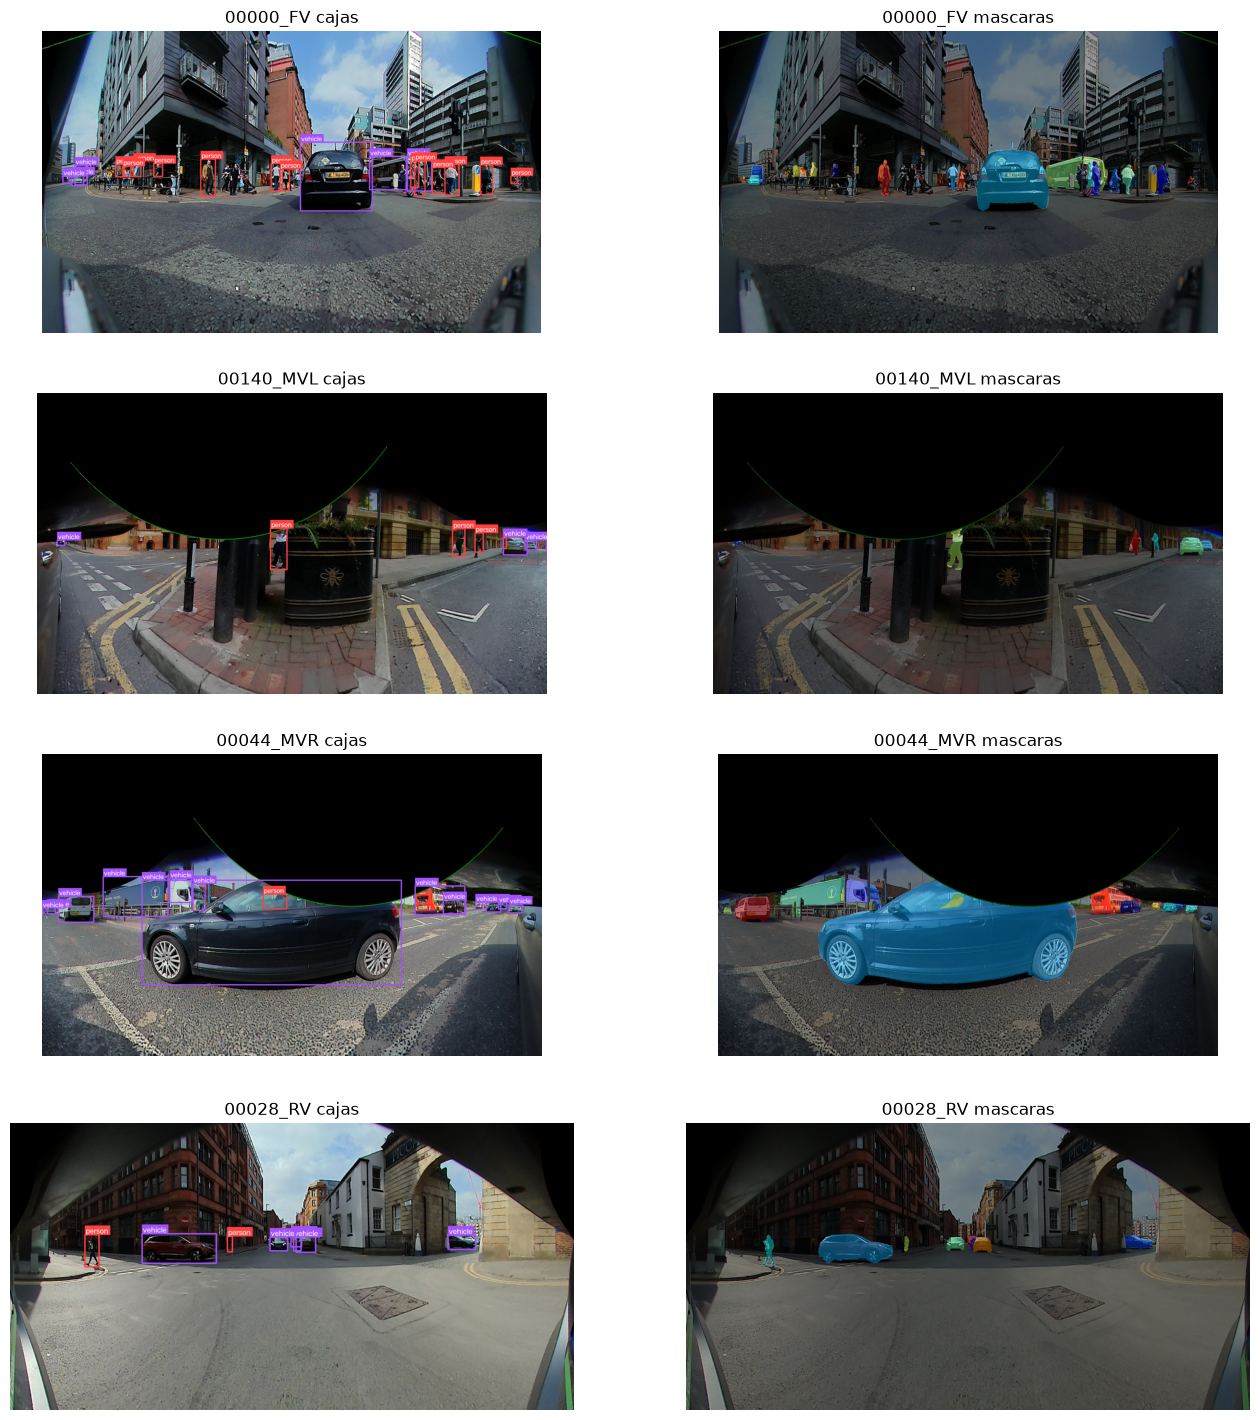

In [6]:
ds_vis = ft.DatasetDeteccion(CIL_DS, "train", mascaras=True)
imgs, titulos = [], []
for cam in ("FV", "MVL", "MVR", "RV"):
    i = next(k for k, s in enumerate(ds_vis.stems) if s.endswith(cam))
    x, t, stem = ds_vis[i]
    img = np.ascontiguousarray((x.permute(1, 2, 0).numpy()[:, :, ::-1] * 255).astype(np.uint8))
    inst = (t["masks"].numpy() * (np.arange(len(t["masks"]))[:, None, None] + 1)).max(0) if len(t["masks"]) else np.zeros(img.shape[:2])
    color = cv2.applyColorMap((inst * 47 % 255).astype(np.uint8), cv2.COLORMAP_JET)
    color[inst == 0] = 0
    imgs += [dibujar(img, t["boxes"].numpy(), t["labels"].numpy() - 1), cv2.addWeighted(img, 0.6, color, 0.4, 0)]
    titulos += [f"{stem} cajas", f"{stem} mascaras"]
sv.plot_images_grid(imgs, grid_size=(4, 2), titles=titulos, size=(16, 18))

### Control: el techo de IoU de la representación con cajas

Las ramas 2 y 4 detectan en la cilíndrica y llevan las cajas de vuelta a la fisheye. Esa vuelta no es gratis: una caja recta en la cilíndrica, al reproyectarse, es un contorno curvo en la fisheye, y la caja que lo encierra puede ser más grande que el objeto.

Para medir cuánto penaliza esto, tomo el ground truth del test y hago el viaje completo con una **detección perfecta**: polígono → caja cilíndrica → `caja_a_fisheye` → comparo contra la caja de referencia. Ese IoU es el techo que ninguna detección de estas ramas puede superar, aunque el modelo fuera perfecto.

In [7]:
techo = []
for fila in tqdm(test.itertuples(), total=len(test), desc="techo de IoU"):
    polis, W, H = ft.poligonos_tp(TEST_DIR / "instance_annotations" / f"{fila.stem}.json")
    assert len(polis) == len(fila.gt_cajas), "el filtro de objetos no coincide con cargar_test"
    mx, my = mapas(fila.calib)
    cajas, _, idx, _, _ = ft.etiquetas_cilindricas(polis, mx, my, W, H)
    vuelta, ok = caja_a_fisheye(cajas, mx, my, W, H)
    iou = {i: (ft.iou_xyxy(v, fila.gt_cajas[i]) if o else np.nan) for i, v, o in zip(idx, vuelta, ok)}
    for i, r in enumerate(radio(fila.gt_cajas, fila)):
        techo.append({"camara": fila.camera, "radio": r, "cubierto": i in iou, "iou": iou.get(i, np.nan)})
techo = pd.DataFrame(techo)
techo["anillo"] = pd.cut(techo["radio"], ANILLOS, labels=NOMBRES_ANILLOS, right=False)
print(f"objetos del test dentro de la banda: {techo['cubierto'].mean():.1%}")
techo[techo["cubierto"]].groupby("anillo", observed=True)["iou"].agg(
    mediana="median", p10=lambda s: s.quantile(0.1), bajo_05=lambda s: (s < 0.5).mean(), n="size").round(3)

techo de IoU: 100%|██████████| 1000/1000 [02:02<00:00,  8.17it/s]

objetos del test dentro de la banda: 96.6%


,mediana,p10,bajo_05,n
anillo,,,,
centro,0.812,0.703,0.000,1887
medio,0.650,0.520,0.069,6656
periferia,0.663,0.489,0.116,2957


`bajo_05` es la fracción de objetos que, incluso detectados perfectamente, no alcanzarían IoU 0,5 al volver a la fisheye y contarían como falso positivo en mAP@50. Es una pérdida estructural de las ramas 2 y 4 que no depende del detector, y hay que reportarla junto con sus métricas.

### Fine-tuning

Cada modelo se reentrena sobre el dataset cilíndrico desde sus pesos COCO. Acá levanto las curvas de los que ya terminaron; los que están a mitad de camino o sin empezar quedan afuera hasta que el script los complete.

In [8]:
TERMINADOS = [m for m in MODELOS if ft.terminado(m, SALIDAS)]
historias = {m: ft.historia(m, SALIDAS) for m in TERMINADOS}
pendientes = [m for m in MODELOS if m not in TERMINADOS]
print(f"terminados: {TERMINADOS}")
print(f"pendientes: {pendientes}" if pendientes else "todos los modelos terminaron")
pd.DataFrame({m: {"epocas": len(h), "mejor mAP50-95 val": h["map50_95"].max()} for m, h in historias.items()}).T.round(3)

terminados: ['yolo11n', 'yolo11s', 'yolo11m']
todos los modelos terminaron


,epocas,mejor mAP50-95 val
yolo11n,30.0,0.344
yolo11s,30.0,0.410
yolo11m,30.0,0.446


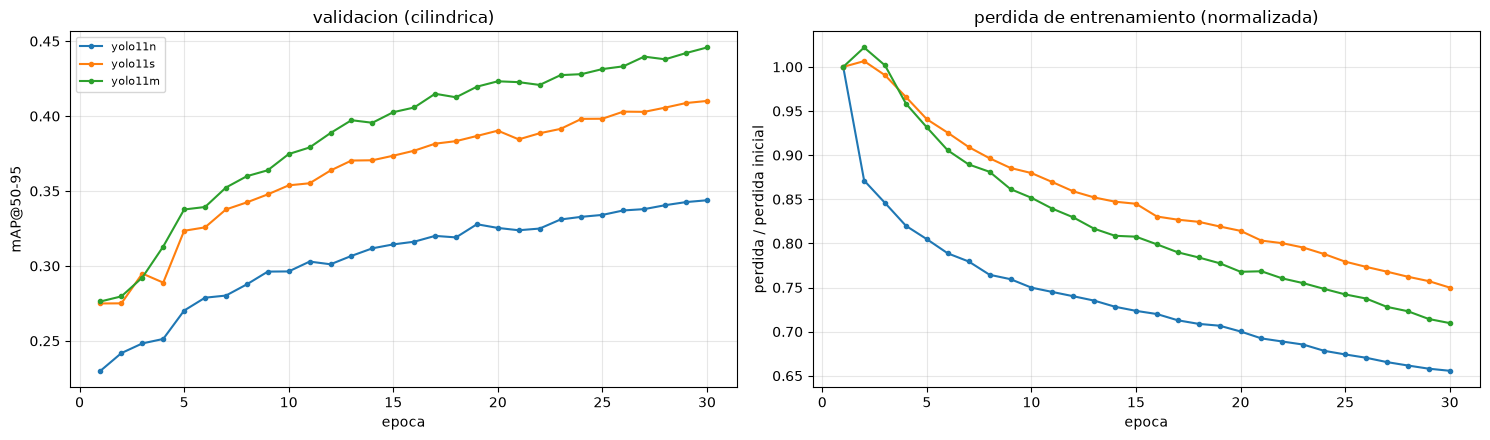

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for nombre, h in historias.items():
    if h.empty:
        continue
    axs[0].plot(h["epoch"], h["map50_95"], marker="o", ms=3, label=nombre)
    axs[1].plot(h["epoch"], h["perdida"] / h["perdida"].iloc[0], marker="o", ms=3, label=nombre)
axs[0].set(xlabel="epoca", ylabel="mAP@50-95", title="validacion (cilindrica)")
axs[1].set(xlabel="epoca", ylabel="perdida / perdida inicial", title="perdida de entrenamiento (normalizada)")
for ax in axs:
    ax.grid(alpha=0.3)
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(SALIDAS / "curvas_entrenamiento.png", dpi=150)
plt.show()

### Inferencia sobre el test

Mismo flujo que la rama 2: fisheye → cilíndrica → detector → cajas de vuelta a la fisheye con `caja_a_fisheye`. La única diferencia es el modelo. Como ya está entrenado con las clases del TP, **no** traduzco clases COCO: la salida ya es vehicle, person y two_wheeler.

El script ya corrió el test de cada modelo apenas terminó de entrenarlo, y acá lo levanto de `outputs/rama4/`. Si falta el de algún modelo terminado (por ejemplo, porque la corrida se cortó justo ahí), lo calculo: son minutos, no horas. Las tres etapas se miden por separado, con diez pasadas de calentamiento y los mapas calculados antes.

In [10]:
preds = {}
for nombre in TERMINADOS:
    best = ft.ruta_best(nombre, SALIDAS)
    barra = tqdm(total=len(test), desc=nombre, disable=(SALIDAS / f"preds_{nombre}_{len(test)}.pkl").exists())
    preds[nombre] = ft.predecir_test(nombre, ft.detector_ft(nombre, best), test, SALIDAS,
                                     progreso=lambda h, t, b=barra: b.update(h - b.n))
    barra.close()
print(f"modelos evaluados: {list(preds)}")

modelos evaluados: ['yolo11n', 'yolo11s', 'yolo11m']


### Visualización

Ground truth sobre la fisheye, detecciones sobre la cilíndrica y las mismas reproyectadas. Uso YOLO11m (o el primer modelo disponible) y un umbral de 0,3 solo para que el dibujo se lea; las métricas usan todas las cajas.

En la rama 2 la carrocería propia generaba falsos `vehicle` en la FV. Como `ego_vehicle` no está entre las etiquetas de entrenamiento, el fine-tuning debería haber aprendido a no detectarla.

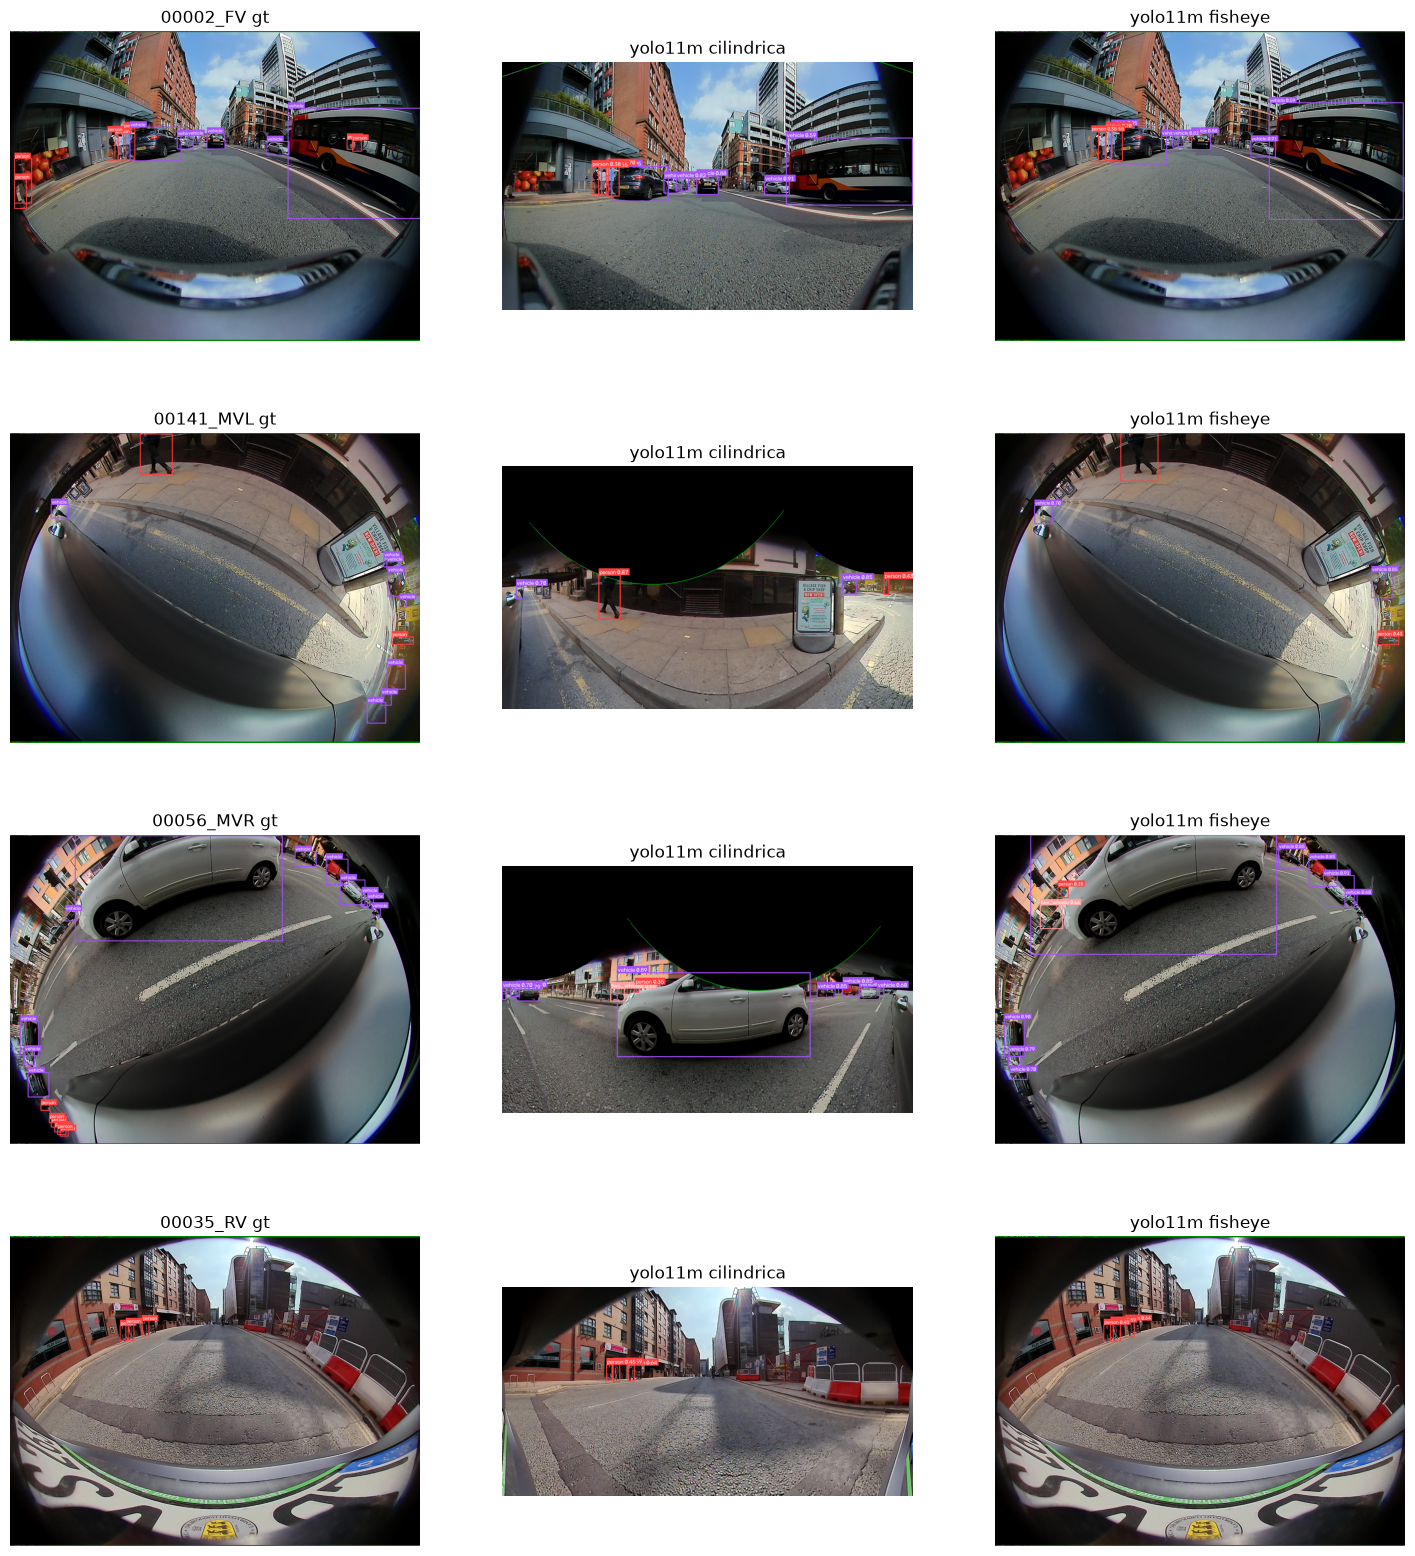

In [11]:
MODELO_VIS = "yolo11m" if "yolo11m" in preds else next(iter(preds))
CONF_VIS = 0.3


def paneles(fila, p):
    """gt en fisheye | pred en cilindrica | pred reproyectada"""
    img = cv2.imread(str(fila.ruta))
    m, mc = p["conf"] >= CONF_VIS, p["conf_cil"] >= CONF_VIS
    cil = dibujar(cilindrica(fila, img), p["cajas_cil"][mc], p["clases_cil"][mc], p["conf_cil"][mc])
    return [dibujar(img, fila.gt_cajas, fila.gt_clases), cil, dibujar(img, p["cajas"][m], p["clases"][m], p["conf"][m])]


pv = preds[MODELO_VIS].set_index("stem")
imgs, titulos = [], []
for fila in test.groupby("camera").head(1).itertuples():
    imgs += paneles(fila, pv.loc[fila.stem])
    titulos += [f"{fila.stem} gt", f"{MODELO_VIS} cilindrica", f"{MODELO_VIS} fisheye"]
sv.plot_images_grid(imgs, grid_size=(4, 3), titles=titulos, size=(18, 20))

(SALIDAS / "vis").mkdir(exist_ok=True)
for fila in test.iloc[::50].itertuples():
    gt, _, pred = paneles(fila, pv.loc[fila.stem])
    cv2.imwrite(str(SALIDAS / "vis" / f"{fila.stem}_{MODELO_VIS}.jpg"), np.hstack([gt, pred]))

### Métricas

Uso la misma función que la rama 2 (`tabla_resultados` de `fisheye_utils.py`), así la comparación 2 contra 4 es directa. Antes pruebo la función con el propio ground truth como predicción, y tiene que dar 1.

In [12]:
gt_como_pred = pd.DataFrame({"stem": test["stem"], "cajas": test["gt_cajas"], "clases": test["gt_clases"],
                             "conf": [np.ones(len(c), dtype=np.float32) for c in test["gt_clases"]]})
m50, m5095 = evaluar(gt_como_pred, test)
assert m50 > 0.99 and m5095 > 0.99, (m50, m5095)

resultados = tabla_resultados(preds, test)
resultados.to_csv(SALIDAS / "resultados.csv")
resultados.round(3)

,mAP50,mAP50-95,mAP50 centro,mAP50-95 centro,mAP50 medio,mAP50-95 medio,mAP50 periferia,mAP50-95 periferia,ms_pre,ms_inf,ms_post,ms_total,fps
modelo,,,,,,,,,,,,,
yolo11n,0.445,0.150,0.571,0.269,0.449,0.140,0.306,0.100,4.295,29.442,4.362,38.099,26.248
yolo11s,0.495,0.163,0.657,0.311,0.493,0.150,0.367,0.114,4.307,31.311,3.645,39.263,25.469
yolo11m,0.521,0.172,0.670,0.323,0.522,0.159,0.389,0.120,4.297,37.407,3.364,45.068,22.189


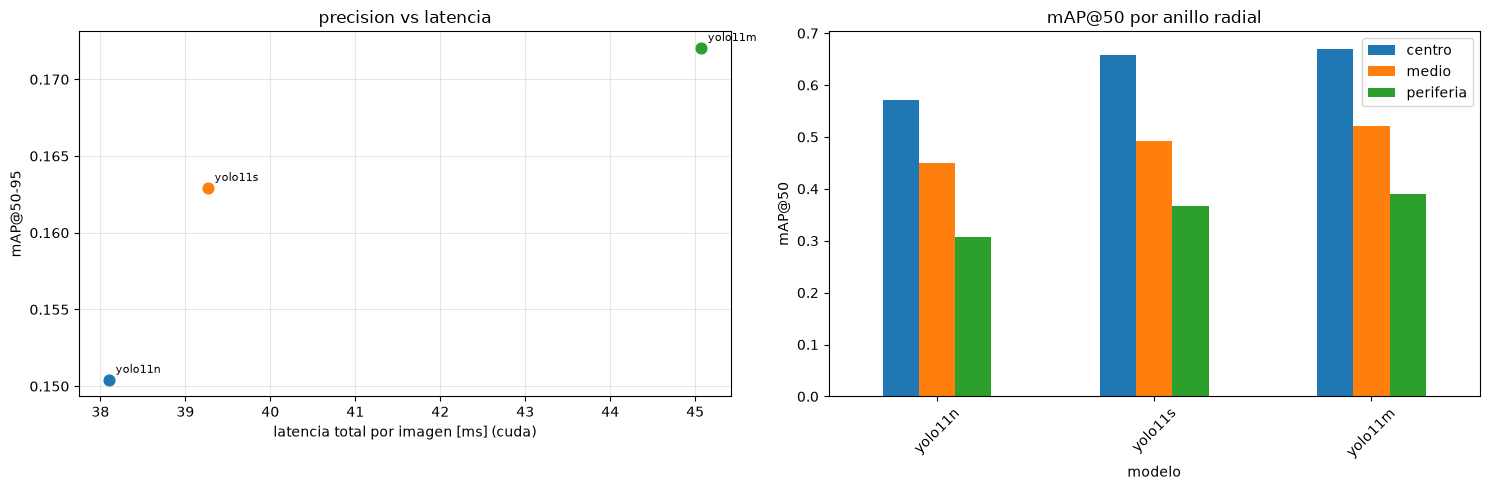

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for nombre, f in resultados.iterrows():
    axs[0].scatter(f["ms_total"], f["mAP50-95"], s=60)
    axs[0].annotate(nombre, (f["ms_total"], f["mAP50-95"]), textcoords="offset points", xytext=(5, 5), fontsize=8)
axs[0].set(xlabel=f"latencia total por imagen [ms] ({DEVICE})", ylabel="mAP@50-95", title="precision vs latencia")
axs[0].grid(alpha=0.3)
resultados[[f"mAP50 {a}" for a in NOMBRES_ANILLOS]].plot.bar(ax=axs[1], rot=45)
axs[1].set(ylabel="mAP@50", title="mAP@50 por anillo radial")
axs[1].legend(NOMBRES_ANILLOS)
plt.tight_layout()
plt.savefig(SALIDAS / "precision_latencia_anillos.png", dpi=150)
plt.show()

#### Comparación con la rama 2

La resta rama 4 − rama 2 es el efecto del fine-tuning con la geometría ya corregida. Necesita `outputs/rama2/resultados.csv`, que se genera corriendo `rama2_cilindrica.ipynb`. Conviene correrlo en la misma máquina que esta rama: así las latencias de las dos van en la misma tabla.

La columna que importa es la de periferia. Un modelo puede subir el mAP global sin mejorar nada ahí.

,Δ mAP50,Δ mAP50-95,Δ mAP50 centro,Δ mAP50 periferia,Δ mAP50-95 periferia
modelo,,,,,
yolo11n,0.151,0.041,0.166,0.139,0.041
yolo11s,0.130,0.026,0.164,0.123,0.031
yolo11m,0.104,0.017,0.112,0.099,0.020


,caida centro→periferia rama 2,caida centro→periferia rama 4
modelo,,
yolo11n,0.586,0.464
yolo11s,0.506,0.442
yolo11m,0.480,0.419


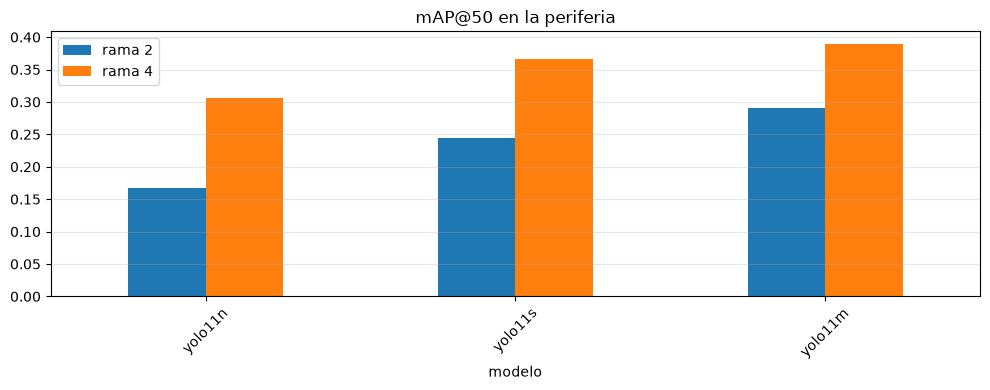

In [17]:
R2 = RAIZ / "outputs/rama2/resultados.csv"
cols = ["mAP50", "mAP50-95", "mAP50 centro", "mAP50 periferia", "mAP50-95 periferia"]
if PRUEBA:
    print("en modo prueba no comparo: la rama 2 esta evaluada sobre las 1000 imagenes")
elif not R2.exists():
    print(f"falta {R2}: correr rama2_cilindrica.ipynb en esta maquina")
else:
    r2 = pd.read_csv(R2, index_col="modelo")
    comunes = [m for m in resultados.index if m in r2.index]
    delta = (resultados.loc[comunes, cols] - r2.loc[comunes, cols]).add_prefix("Δ ")
    caida = pd.DataFrame({
        "caida centro→periferia rama 2": 1 - r2.loc[comunes, "mAP50 periferia"] / r2.loc[comunes, "mAP50 centro"],
        "caida centro→periferia rama 4": 1 - resultados.loc[comunes, "mAP50 periferia"] / resultados.loc[comunes, "mAP50 centro"],
    })
    display(delta.round(3))
    display(caida.round(3))

    ax = pd.DataFrame({"rama 2": r2.loc[comunes, "mAP50 periferia"], "rama 4": resultados.loc[comunes, "mAP50 periferia"]}).plot.bar(
        rot=45, figsize=(10, 4), title="mAP@50 en la periferia")
    ax.grid(alpha=0.3, axis="y")
    plt.tight_layout()
    plt.savefig(SALIDAS / "rama2_vs_rama4_periferia.png", dpi=150)
    plt.show()

#### Evaluación por ángulo de incidencia

`tabla_resultados` estratifica por distancia al centro en píxeles con cortes fijos. La rama 1 usa `eval_radial.py`, que estratifica por el ángulo de incidencia θ que sale de la calibración, con los cortes congelados de `rings.json` (68,3° y 80,7°) y el esquema *ignore* de COCO entre anillos. Exporto las predicciones al formato de ese script para tener las cuatro ramas también con esa métrica.

Los números de las dos métricas **no** se comparan entre sí, solo entre ramas dentro de la misma métrica.

In [18]:
theta = None
if PRUEBA:
    print("en modo prueba no corro eval_radial: evalua contra las 1000 imagenes del test")
elif not (EVAL_RADIAL.is_file() and CALIBRACION.is_file() and (YOLO_DS / "rings.json").is_file()):
    print("falta eval_radial.py, calibration.json o rings.json en CV2/")
else:
    filas = []
    for nombre, p in preds.items():
        pj, out = SALIDAS / "pred_json" / f"{nombre}.json", SALIDAS / "eval_radial" / nombre
        ft.a_pred_json(p, pj)
        r = subprocess.run([sys.executable, str(EVAL_RADIAL), "--yolo-dir", str(YOLO_DS), "--split", "test",
                            "--pred-json", str(pj), "--out", str(out), "--calibration", str(CALIBRACION),
                            "--rings-file", str(YOLO_DS / "rings.json"), "--etiqueta", f"rama4_{nombre}", "--cruce-tamano"],
                           capture_output=True, text=True)
        if r.returncode:
            print(f"[{nombre}] eval_radial fallo:\n{r.stderr[-1000:]}")
            continue
        fila = {"modelo": nombre}
        for f in json.loads((out / "metricas.json").read_text(encoding="utf-8"))["filas"]:
            if f["clase"] == "TODAS":
                fila[f"mAP50 {f['rango']}"], fila[f"mAP50-95 {f['rango']}"] = f["AP50"], f["AP50_95"]
        filas.append(fila)
    theta = pd.DataFrame(filas).set_index("modelo")
    theta.to_csv(SALIDAS / "resultados_theta.csv")
    display(theta.round(3))

,mAP50 global,mAP50-95 global,mAP50 centro,mAP50-95 centro,mAP50 medio,mAP50-95 medio,mAP50 periferia,mAP50-95 periferia
modelo,,,,,,,,
yolo11n,0.445,0.150,0.561,0.220,0.442,0.134,0.336,0.105
yolo11s,0.495,0.163,0.619,0.243,0.488,0.143,0.390,0.116
yolo11m,0.521,0.172,0.642,0.254,0.521,0.152,0.412,0.122


#### Por cámara

In [19]:
por_cam = pd.DataFrame({
    nombre: {cam: evaluar(p, test[test["camera"] == cam])[0] for cam in sorted(test["camera"].unique())}
    for nombre, p in preds.items()
}).T
por_cam.round(3)

,FV,MVL,MVR,RV
yolo11n,0.541,0.366,0.400,0.475
yolo11s,0.598,0.411,0.445,0.528
yolo11m,0.624,0.453,0.467,0.548


### Conclusiones

**Mejor modelo.** Entre los tres YOLO reentrenados, YOLO11m es el más preciso en todas las métricas: mAP@50 de 0,521 global y de 0,389 en la periferia. El orden n < s < m se mantiene en todos los anillos y en las cuatro cámaras. En la GTX 1660 la latencia total casi no separa a los modelos: 38 ms para n, 39 ms para s y 45 ms para m. Buena parte de ese tiempo es preprocesamiento, proyección y posprocesamiento, que no dependen del tamaño de la red. Con eso, YOLO11m es la elección razonable: pasar de s a m cuesta 6 ms y suma 0,026 de mAP@50. YOLO11s queda en el codo solo si la latencia es una restricción fuerte. Estas latencias no se pueden comparar con las de la rama 2, que se midieron en otra máquina (Mac con MPS).

**Efecto del fine-tuning con la geometría corregida.** Contra la rama 2 (mismos modelos, misma proyección, mismo test, sin reentrenar), el fine-tuning sube el mAP@50 global entre 0,10 y 0,15. La mejora es mayor cuanto más chico es el modelo: +0,151 en n, +0,130 en s y +0,104 en m. El caso más claro es YOLO11n fine-tuneado (0,445), que ya supera a YOLO11x de la rama 2 sin reentrenar (0,437) con una fracción de los parámetros. Adaptar el modelo al dominio pesa más que agrandarlo.

**La periferia.** En términos relativos, la ganancia se concentra donde el modelo partía peor. En la periferia el mAP@50 pasa de 0,170 a 0,306 en n (+80%), de 0,243 a 0,367 en s (+51%) y de 0,292 a 0,389 en m (+33%). La caída relativa del centro a la periferia se achica en los tres modelos: de 59% a 46% en n, de 51% a 44% en s y de 48% a 42% en m. O sea, el fine-tuning no se limita a mejorar donde ya andaba bien: también cierra parte de la brecha radial. Pero la brecha no desaparece. Aun con la geometría corregida y el modelo adaptado, en la periferia se pierde más del 40% del mAP@50 del centro.

**Estratificación por ángulo de incidencia.** Con `eval_radial` (cortes en θ de 68,3° y 80,7° e *ignore* entre anillos) los globales coinciden con los de `tabla_resultados`, y la periferia sale un poco mejor: 0,336, 0,390 y 0,412. La caída del centro a la periferia queda entre 36% y 40%. La diferencia con la estratificación por píxeles se explica porque el anillo exterior en radio normalizado mezcla objetos de distinto θ según la cámara y la calibración. La tendencia es la misma con las dos métricas, así que la conclusión no depende de cómo se defina el anillo.

**Por cámara.** La FV es la que mejor anda (0,62 de mAP@50 con m) y las laterales MVL y MVR las peores (0,45 y 0,47). Lo mismo pasa en los tres modelos, así que parece venir de la escena (objetos más cercanos, más oclusión y más deformados en las laterales) más que del detector.

**El techo de la representación con cajas.** La mejora en mAP@50-95 es mucho menor que en mAP@50: +0,02 a +0,04 global, y en la periferia queda entre 0,10 y 0,12. El control del techo de IoU explica buena parte de esto. Incluso con una detección perfecta en la cilíndrica, al reproyectar la caja a la fisheye la IoU mediana es 0,81 en el centro, pero 0,65 en el anillo medio y 0,66 en la periferia. Además, el 6,9% de los objetos del anillo medio y el 11,6% de los de la periferia ni siquiera llegarían a IoU 0,5. A eso se suma que el 3,4% de los objetos del test cae fuera de la banda de ±45° y es irrecuperable para las ramas 2 y 4. Es una pérdida estructural del enfoque "rectificar, detectar con cajas y volver": ningún entrenamiento la recupera, y a umbrales de IoU altos domina el resultado. Con la métrica en la fisheye, rectificar tiene un costo que el fine-tuning no puede compensar.

**Limitaciones.** Entrené solo tres modelos (YOLO11 n, s y m) por el costo computacional en una GTX 1660 de 6 GB, que obligó a batches chicos (8, 4 y 2, con acumulación de gradiente hasta 64) y a desactivar AMP. Usé una sola semilla, así que no tengo la varianza entre corridas para saber cuánto de las diferencias chicas (del orden de 0,02) es ruido. Las curvas de validación de los tres modelos todavía subían en la época 30, así que con más épocas probablemente mejoren algo más.

**Próximos pasos.** Falta el contraste con la rama 3 (fine-tuning sobre la fisheye sin rectificar). Es el que dice si, una vez que el modelo se adapta, conviene seguir rectificando. Si la rama 3 iguala o supera a la rama 4 en la periferia, el techo de IoU de la reproyección haría que la rectificación no valga la pena. Si queda por debajo, la geometría corregida seguiría aportando algo que el modelo no aprende solo. Para cerrar el factorial hay que evaluar las cuatro ramas con `eval_radial` sobre las mismas 1000 imágenes y estimar la interacción con (rama 4 − rama 3) − (rama 2 − rama 1).